### Das Halteproblem

[Video](https://youtu.be/kF0kgEX0oqQ)

In diesem Notebook geht es um Probleme, die kein Algorithmus lösen kann. Nicht weil die Rechner zu langsam sind,
sondern grundsätzlich: Es kann kein Programm geben, das sie für alle Eingaben richtig beantwortet.

- Das **Halteproblem**: Hält ein Programm an oder läuft es endlos?
- Das **Postsche Korrespondenzproblem**: ein Legespiel mit Dominosteinen.
- **Unendliche Mengen**: Es gibt verschieden große Unendlichkeiten. Daraus folgt, dass es viel mehr Probleme als
  Algorithmen gibt.

#### Entscheidungsprobleme

Ein **Entscheidungsproblem** ist eine Frage, die für jede Eingabe mit Ja oder Nein beantwortet wird, z.B.: Ist die
Zahl `n` eine Primzahl?

Ein Algorithmus **entscheidet** das Problem, wenn er für jede Eingabe nach endlich vielen Schritten anhält und die
richtige Antwort liefert. In Python ist das eine Funktion, die immer `True` oder `False` zurückgibt.

In [1]:
def istPrim(n):
    if n < 2:
        return False
    for t in range(2, n):
        if n % t == 0:
            return False
    return True

print([n for n in range(30) if istPrim(n)])

[2, 3, 5, 7, 11, 13, 17, 19, 23, 29]


Gibt es einen solchen Algorithmus, dann heißt das Problem **entscheidbar**, sonst **unentscheidbar** (oder
algorithmisch nicht entscheidbar).

#### Hält ein Programm an?

Nicht jedes Programm hält an. Die folgende Funktion hält für `endlos(4)`: `n` wird 2 und dann 0. Für `endlos(5)`
wird `n` zu 3, 1, -1, -3, ... und erreicht nie die 0. Diese Zelle führen wir deshalb nicht aus.

```python
def endlos(n):
    while n != 0:
        n = n - 2
```

Hier sieht man sofort, wann die Funktion hält. Oft ist das viel schwieriger. Die nächste Funktion halbiert eine
gerade Zahl, eine ungerade Zahl wird mit 3 multipliziert und um 1 erhöht. Das wird wiederholt, bis die 1 erreicht
ist.

In [2]:
def collatz(n):
    folge = [n]
    while n != 1:
        if n % 2 == 0:
            n = n // 2
        else:
            n = 3 * n + 1
        folge.append(n)
    return folge

print(collatz(6))
print(len(collatz(27)) - 1, max(collatz(27)))

[6, 3, 10, 5, 16, 8, 4, 2, 1]
111 9232


Für 6 hält die Funktion nach 8 Schritten. Für 27 braucht sie schon 111 Schritte und kommt dabei bis 9232. Wir
probieren alle Zahlen bis 100000 aus:

In [3]:
schritte = [len(collatz(n)) - 1 for n in range(1, 100001)]
print(max(schritte), schritte.index(max(schritte)) + 1)

350 77031


Alle diese Aufrufe halten, am längsten braucht 77031 mit 350 Schritten. Ob die Funktion für **jede** natürliche
Zahl anhält, weiß bis heute niemand. Das ist die **Collatz-Vermutung**. Mit Rechnern wurde sie für alle Zahlen bis
über $10^{20}$ geprüft, bewiesen ist sie nicht.

Ein Programm, das für jedes Programm vorhersagt, ob es anhält, wäre also sehr nützlich. Das ist das **Halteproblem**:

> Gegeben sind ein Programm `pgm` und eine Eingabe `inp`. Hält `pgm` angesetzt auf `inp` nach endlich vielen
> Schritten an?

Warum nicht einfach ausprobieren? Wenn das Programm anhält, merken wir das irgendwann. Wenn es aber nach einer
Stunde immer noch läuft, wissen wir nicht, ob es nie anhält oder ob es nur noch etwas länger braucht.

#### Programme als Eingabe

Für den Beweis brauchen wir Programme, die andere Programme als Eingabe bekommen. In Python kann man einer Funktion
eine andere Funktion übergeben:

In [4]:
def verdoppeln(x):
    return 2 * x

def zweimal(f, x):
    return f(f(x))

print(zweimal(verdoppeln, 5))

20


Ein Programm ist außerdem nur ein Text, den man wie jeden anderen Text als Eingabe übergeben kann:

In [5]:
import inspect

text = inspect.getsource(verdoppeln)
print(text)
print(len(text), 'Zeichen')

def verdoppeln(x):
    return 2 * x

36 Zeichen


Ein Programm kann deshalb auch sich selbst als Eingabe bekommen. Das klingt seltsam, ist aber erlaubt.

#### Das Halteproblem ist unentscheidbar

> Es gibt keinen Algorithmus, der für alle Programme und alle Eingaben entscheidet, ob das Programm angesetzt auf die
> Eingabe anhält.

Wir beweisen das durch **Widerspruch**. Wir nehmen an, es gäbe eine Funktion `haltetest`, die das Halteproblem
löst. Was in ihrem Rumpf steht, wissen wir nicht, deshalb steht dort nur `...`. Mit `haltetest` schreiben wir eine
zweite Funktion `quer`:

In [6]:
def haltetest(pgm, inp):
    '''gibt True zurück, wenn pgm angesetzt auf inp anhält, sonst False'''
    ...

def quer(x):
    if haltetest(x, x):
        while True:
            pass

`quer` fragt, ob das Programm `x` angesetzt auf sich selbst anhält. Wenn ja, läuft `quer` in eine Endlosschleife.
Wenn nein, ist `quer` sofort fertig. `quer` macht also immer das Gegenteil von dem, was `x` mit sich selbst macht.

Jetzt fragen wir: Hält `quer(quer)` an? Es gibt nur zwei Möglichkeiten.

- **Fall 1:** `quer(quer)` hält an. Dann liefert `haltetest(quer, quer)` den Wert `True`. Also läuft `quer(quer)`
  in die Endlosschleife und hält nicht an. Widerspruch.
- **Fall 2:** `quer(quer)` hält nicht an. Dann liefert `haltetest(quer, quer)` den Wert `False`. Also ist
  `quer(quer)` sofort fertig und hält an. Widerspruch.

In beiden Fällen erhalten wir einen Widerspruch. An `quer` ist nichts verboten: eine Abfrage und eine Schleife.
Falsch sein kann nur die Annahme, dass es `haltetest` gibt. Also gibt es keine solche Funktion.

Wir können das an einem Versuch sehen. Diese Fassung von `haltetest` behauptet immer, dass das Programm nicht
anhält:

In [7]:
def haltetest(pgm, inp):
    return False

quer(quer)
print('quer(quer) hat angehalten, haltetest(quer, quer) sagt aber', haltetest(quer, quer))

quer(quer) hat angehalten, haltetest(quer, quer) sagt aber False


Eine Fassung, die bei `quer(quer)` den Wert `True` liefert, irrt sich ebenfalls: Dann läuft `quer(quer)` endlos.
Das gilt für jede Funktion `haltetest`, egal wie geschickt sie programmiert ist: Bei `quer(quer)` mit genau dieser
Funktion `haltetest` liegt sie falsch.

#### Was bedeutet das?

- Kein Werkzeug kann für beliebige Programme zuverlässig Endlosschleifen finden. Es gibt Werkzeuge, die viele Fälle
  erkennen, aber bei manchen Programmen müssen sie sich irren oder mit „weiß nicht“ antworten.
- Viele andere Fragen über Programme sind aus demselben Grund unentscheidbar, z.B. ob ein Programm jemals `Hallo`
  ausgibt. Könnte man eine solche Frage entscheiden, dann könnte man damit auch `haltetest` bauen (siehe Aufgaben).

### Das Postsche Korrespondenzproblem (PKP)

Gegeben sind endlich viele Typen von Dominosteinen, auf denen oben und unten ein Wort steht, z.B. eine Folge aus 0
und 1. Von jedem Typ stehen beliebig viele Steine zur Verfügung. Kann man eine Folge von Steinen finden, so dass sich
oben und unten das gleiche Gesamtwort ergibt?

Ein Beispiel mit drei Typen, geschrieben als (oben, unten):

    1: (1, 101)   2: (10, 00)   3: (011, 11)

Mit der Folge 1, 3, 2, 3 ergibt sich oben und unten `101110011`. Die Funktion `legen` setzt die Wörter einer Folge
zusammen:

In [8]:
def legen(steine, folge):
    oben = ''
    unten = ''
    for nr in folge:
        oben = oben + steine[nr][0]
        unten = unten + steine[nr][1]
    return oben, unten

steine1 = {1: ('1', '101'), 2: ('10', '00'), 3: ('011', '11')}
print(legen(steine1, [1, 3, 2, 3]))

('101110011', '101110011')


Schon bei kleinen Beispielen können die Lösungen sehr lang werden. Bei diesen vier Typen besteht eine kürzeste
Lösung aus 66 Steinen:

    1: (001, 0)   2: (01, 011)   3: (01, 101)   4: (10, 001)

In [9]:
steine2 = {1: ('001', '0'), 2: ('01', '011'), 3: ('01', '101'), 4: ('10', '001')}
folge2 = [2, 4, 3, 4, 4, 2, 1, 2, 4, 3, 4, 3, 4, 4, 3, 4, 4, 2, 1, 4, 4, 2, 1, 3, 4, 1, 1, 3, 4, 4, 4, 2, 1, 2,
          1, 1, 1, 3, 4, 3, 4, 1, 2, 1, 4, 4, 2, 1, 4, 1, 1, 3, 4, 1, 1, 3, 1, 1, 3, 1, 2, 1, 4, 1, 1, 3]
oben, unten = legen(steine2, folge2)
print(len(folge2), oben == unten, len(oben))
print(oben)

66 True 154
0110011010010010110011001101001101001001101001001011000100101101010010010100100100101100110001010011010010011000100101100010010100100101001010011000100101


#### Lösungen suchen

Man könnte alle Folgen der Länge 1, 2, 3, ... ausprobieren. Bei vier Typen gibt es aber $4^{66}$ Folgen der Länge
66:

In [10]:
print(4 ** 66)

5444517870735015415413993718908291383296


Das geht geschickter. Nach jedem Stein muss das kürzere der beiden Wörter ein Anfang des längeren sein, sonst kann
daraus keine Lösung mehr werden. Was am längeren Wort übersteht, nennen wir den **Überhang**. Für die weiteren Steine
kommt es nur auf den Überhang an, nicht auf die Steine davor.

Beispiel mit `steine1`: Nach Stein 1 steht oben `1`, unten `101`, der Überhang ist `01` unten. Nach Stein 3 steht
oben `1011`, unten `10111`, der Überhang ist `1` unten.

Die Überhänge sind die Zustände einer **Breitensuche**. Ein Stein führt von einem Überhang zum nächsten. Die Suche
ist am Ziel, wenn kein Überhang mehr bleibt. Weil die Breitensuche die Zustände nach der Zahl der Steine abarbeitet,
findet sie eine kürzeste Lösung.

In [11]:
from collections import deque

def pkp_suche(steine, max_zustaende=1000000):
    start = ('', '')
    vorgaenger = {start: None}
    schlange = deque([start])
    while schlange:
        zustand = schlange.popleft()
        for nr in steine:
            oben = zustand[0] + steine[nr][0]
            unten = zustand[1] + steine[nr][1]
            if oben.startswith(unten):
                neu = (oben[len(unten):], '')
            elif unten.startswith(oben):
                neu = ('', unten[len(oben):])
            else:
                continue
            if neu == ('', ''):
                folge = [nr]
                while vorgaenger[zustand] is not None:
                    zustand, nr = vorgaenger[zustand]
                    folge.append(nr)
                return folge[::-1]
            if neu not in vorgaenger:
                vorgaenger[neu] = (zustand, nr)
                schlange.append(neu)
        if len(vorgaenger) > max_zustaende:
            return 'abgebrochen'
    return 'keine Lösung'

print(pkp_suche(steine1))
loesung = pkp_suche(steine2)
print(len(loesung), loesung == folge2)

[1, 3, 2, 3]
66 True


Die Suche findet in kurzer Zeit genau die Lösung mit 66 Steinen von oben.

Bei diesen beiden Typen passt kein Stein am Anfang, die Suche endet sofort ohne Lösung:

In [12]:
steine3 = {1: ('0', '1'), 2: ('01', '00')}
print(pkp_suche(steine3))

keine Lösung


Bei den nächsten beiden Typen ist das obere Wort immer um ein Zeichen länger als das untere. Oben und unten können
also nie gleich lang werden, es gibt keine Lösung. Die Suche merkt das aber nicht: Der Überhang wird immer länger,
es entstehen immer neue Zustände. Ohne die Grenze `max_zustaende` liefe sie endlos.

In [13]:
steine4 = {1: ('00', '0'), 2: ('01', '0')}
print(pkp_suche(steine4, 1000))

abgebrochen


Das ist typisch für das PKP: Gibt es eine Lösung, dann findet die Suche sie irgendwann. Gibt es keine, dann kann die
Suche endlos laufen. Ein solches Verfahren, das bei Ja-Antworten sicher anhält, bei Nein-Antworten aber vielleicht
nie, heißt **semi-entscheidbar**. Das Halteproblem ist ebenso semi-entscheidbar: Man lässt das Programm laufen und
antwortet Ja, sobald es anhält.

#### Unentscheidbarkeit des PKP

> Es gibt keinen Algorithmus, der für beliebige PKP-Instanzen entscheiden kann, ob es eine Lösung gibt.

Das hat Emil Post 1946 bewiesen. Die Idee: Zu jedem Programm mit Eingabe kann man Dominosteine konstruieren, deren
Gesamtwort den Ablauf des Programms Schritt für Schritt aufschreibt. Die Steine haben genau dann eine Lösung, wenn
das Programm anhält. Ein Algorithmus für das PKP würde also das Halteproblem lösen, und den gibt es nicht. Eine
solche Rückführung eines Problems auf ein anderes heißt **Reduktion**.

Das PKP ist interessant, weil es mit Programmen auf den ersten Blick nichts zu tun hat. Es ist ein einfaches
Legespiel, und trotzdem kann es kein Programm für alle Fälle lösen. Mit nur zwei Typen von Steinen ist es übrigens
entscheidbar, ab fünf Typen ist es unentscheidbar.

### Unendliche Mengen

Wie viele Probleme sind algorithmisch nicht lösbar? Um das zu beantworten, müssen wir unendliche Mengen vergleichen.

#### Hilberts Hotel

Hilberts Hotel hat unendlich viele Zimmer: 1, 2, 3, ... Alle Zimmer sind belegt.

**Fall 1:** Ein neuer Gast kommt. Kann er noch untergebracht werden?

Ja. Jeder Gast zieht ein Zimmer weiter: Der Gast aus Zimmer $n$ zieht in Zimmer $n + 1$. Danach ist Zimmer 1 frei.

**Fall 2:** Ein Bus mit unendlich vielen neuen Gästen kommt. Können die neuen Gäste noch untergebracht werden?

Ja. Der Gast aus Zimmer $n$ zieht in Zimmer $2n$. Dann sind alle ungeraden Zimmer frei, der Gast mit Platz $k$ im Bus
bekommt Zimmer $2k - 1$.

**Fall 3:** Unendlich viele Busse mit unendlich vielen neuen Gästen kommen. Können die neuen Gäste noch untergebracht
werden?

Auch das geht. Die alten Gäste nennen wir Bus 0, ihr Platz ist ihre alte Zimmernummer. Wir schreiben alle Gäste in
eine Tabelle: Zeile $b$ für den Bus, Spalte $k$ für den Platz. Dann gehen wir die Tabelle schräg ab: zuerst alle
Gäste mit $b + k = 1$, dann alle mit $b + k = 2$, dann $b + k = 3$ usw. Jede Schräge ist endlich, also kommt jeder
Gast irgendwann an die Reihe. So bekommt jeder Gast ein eigenes Zimmer:

In [14]:
def zimmer(b, k):
    s = b + k
    return (s - 1) * s // 2 + b + 1

for b in range(5):
    print('Bus', b, [zimmer(b, k) for k in range(1, 8)])

Bus 0 [1, 2, 4, 7, 11, 16, 22]
Bus 1 [3, 5, 8, 12, 17, 23, 30]
Bus 2 [6, 9, 13, 18, 24, 31, 39]
Bus 3 [10, 14, 19, 25, 32, 40, 49]
Bus 4 [15, 20, 26, 33, 41, 50, 60]


In [15]:
nummern = [zimmer(b, k) for b in range(100) for k in range(1, 101) if b + k <= 100]
print(len(nummern), len(set(nummern)), sorted(nummern) == list(range(1, len(nummern) + 1)))

5050 5050 True


Für alle Gäste mit $b + k \le 100$ prüft die letzte Zelle: Die 5050 Gäste bekommen verschiedene Zimmer, und zwar
genau die Zimmer 1 bis 5050. Kein Zimmer bleibt leer.

#### Gleichmächtige Mengen

Zwei endliche Mengen sind **gleichmächtig**, wenn sie gleich viele Elemente haben. Bei unendlichen Mengen kann man
nicht zählen. Man kann aber Paare bilden:

> Zwei Mengen sind gleichmächtig, wenn man ihre Elemente 1:1 einander zuordnen kann, d.h. wenn es eine bijektive
> Abbildung zwischen ihnen gibt. Jedes Element der einen Menge bekommt genau einen Partner in der anderen Menge,
> und keines bleibt übrig.

Eine Menge, die gleichmächtig zu $\mathbb{N} = \{1, 2, 3, \dots\}$ ist, heißt **abzählbar unendlich**. Man kann ihre
Elemente durchnummerieren, so dass jedes Element genau eine Nummer bekommt.

**$\mathbb{N}$ und $\mathbb{N}_0$ sind gleichmächtig.** Die Zuordnung ist $n \mapsto n - 1$. Das ist Fall 1 im
Hotel.

<img src="bild1.png" width="500">

**$\mathbb{N}$ und $\mathbb{Z}$ sind gleichmächtig.** Die geraden Zahlen werden den positiven ganzen Zahlen
zugeordnet, die ungeraden der 0 und den negativen.

<img src="bild2.png" width="500">

In [16]:
def nachZ(n):
    if n % 2 == 0:
        return n // 2
    else:
        return -(n - 1) // 2

print([nachZ(n) for n in range(1, 12)])

[0, 1, -1, 2, -2, 3, -3, 4, -4, 5, -5]


$\mathbb{N}$ ist eine echte Teilmenge von $\mathbb{Z}$ und trotzdem gleichmächtig. Bei endlichen Mengen geht das
nicht, bei unendlichen schon.

**$\mathbb{N}$ und $\mathbb{Q}^+$ sind gleichmächtig.** Wir schreiben alle positiven Brüche in eine Tabelle: In
Zeile $p$ stehen die Brüche mit Zähler $p$, in Spalte $q$ die mit Nenner $q$. Diese Tabelle gehen wir schräg ab wie
die Busse im Hotel. Brüche, die sich kürzen lassen, überspringen wir, sie sind schon vorgekommen ($\frac{2}{2} =
\frac{1}{1}$). Diese Abzählung stammt von Georg Cantor.

<img src="cantor.png" width="450">

In [17]:
from math import gcd

def cantor(anzahl):
    brueche = []
    s = 2
    while len(brueche) < anzahl:
        paare = [(p, s - p) for p in range(1, s)]
        if s % 2 == 0:
            paare.reverse()
        for p, q in paare:
            if gcd(p, q) == 1 and len(brueche) < anzahl:
                brueche.append(f'{p}/{q}')
        s = s + 1
    return brueche

print(cantor(15))

['1/1', '1/2', '2/1', '3/1', '1/3', '1/4', '2/3', '3/2', '4/1', '5/1', '1/5', '1/6', '2/5', '3/4', '4/3']


In jeder Schräge ist die Summe $s = p + q$ gleich. Bei geradem $s$ wird die Schräge von unten nach oben
durchlaufen, bei ungeradem von oben nach unten.

**$\mathbb{N}$ und $\mathbb{Q}$ sind gleichmächtig.** Wir nehmen die Abzählung von $\mathbb{Q}^+$ und setzen nach
jedem Bruch den negativen Bruch ein, an den Anfang kommt die 0.

In [18]:
q = ['0']
for b in cantor(7):
    q = q + [b, '-' + b]
print(q)

['0', '1/1', '-1/1', '1/2', '-1/2', '2/1', '-2/1', '3/1', '-3/1', '1/3', '-1/3', '1/4', '-1/4', '2/3', '-2/3']


#### Überabzählbare Mengen

Nicht jede unendliche Menge ist abzählbar. Wir betrachten unendliche Folgen aus 0 und 1, z.B.

    0 1 0 1 0 1 0 1 ...
    1 1 1 1 1 1 1 1 ...
    0 1 1 0 1 0 1 0 ...   (an den Stellen 2, 3, 5, 7, 11, ... eine 1)

**Die Menge aller 0-1-Folgen ist nicht abzählbar.** Beweis durch Widerspruch: Angenommen, es gäbe eine
Nummerierung $f_1, f_2, f_3, \dots$ aller Folgen. Wir bauen eine neue Folge $d$: An der Stelle $i$ hat $d$ das
Gegenteil der $i$-ten Stelle von $f_i$. Dann unterscheidet sich $d$ von $f_1$ an der Stelle 1, von $f_2$ an der
Stelle 2, allgemein von $f_i$ an der Stelle $i$. Also kommt $d$ in der Nummerierung nicht vor. Widerspruch.

Weil man dafür die Diagonale der Tabelle benutzt, heißt das Verfahren **Diagonalverfahren**. Hier für die ersten
sechs Stellen von sechs Folgen:

In [19]:
folgen = ['010101', '111111', '011010', '000000', '100100', '110011']
d = ''
for i in range(len(folgen)):
    if folgen[i][i] == '0':
        d = d + '1'
    else:
        d = d + '0'
for i in range(len(folgen)):
    print(folgen[i], 'Stelle', i + 1, folgen[i][i], '->', d[i])
print(d, d in folgen)

010101 Stelle 1 0 -> 1
111111 Stelle 2 1 -> 0
011010 Stelle 3 1 -> 0
000000 Stelle 4 0 -> 1
100100 Stelle 5 0 -> 1
110011 Stelle 6 1 -> 0
100110 False


Egal welche Liste man nimmt, die Diagonalfolge fehlt immer. Eine Menge, die unendlich, aber nicht abzählbar ist,
heißt **überabzählbar**.

Eine 0-1-Folge kann man auch als Teilmenge von $\mathbb{N}$ lesen: Eine 1 an der Stelle $i$ heißt, $i$ gehört zur
Teilmenge. Die dritte Folge oben ist die Menge der Primzahlen. Die Menge aller Teilmengen von $\mathbb{N}$ ist also
ebenfalls überabzählbar.

**Das Intervall $(0, 1)$ ist überabzählbar.** Das geht genauso mit Dezimalzahlen. Angenommen, $z_1, z_2, z_3, \dots$
wären alle Zahlen zwischen 0 und 1. Wir bilden eine Zahl $x = 0{,}x_1 x_2 x_3 \dots$: Ist die $i$-te
Nachkommastelle von $z_i$ eine 5, dann ist $x_i = 4$, sonst $x_i = 5$. Dann unterscheidet sich $x$ von jedem $z_i$
an der Stelle $i$ und liegt zwischen 0 und 1. Die Ziffern 4 und 5 nehmen wir, weil es Zahlen mit zwei
Schreibweisen gibt, z.B. $0{,}1 = 0{,}0999\dots$. Mit 4 und 5 entsteht keine solche Zahl.

In [20]:
zahlen = ['0.141592', '0.555555', '0.333333', '0.718281', '0.414213', '0.250000']
x = '0.'
for i in range(len(zahlen)):
    if zahlen[i][i + 2] == '5':
        x = x + '4'
    else:
        x = x + '5'
print(x, x in zahlen)

0.545555 False


**$(0, 1)$ und $\mathbb{R}$ sind gleichmächtig.** Die Funktion $f(x) = \tan(\pi x - \frac{\pi}{2})$ ordnet jeder
Zahl zwischen 0 und 1 genau eine reelle Zahl zu, und jede reelle Zahl kommt genau einmal als Funktionswert vor.
Die Kurve steigt immer und geht bei 0 gegen $-\infty$, bei 1 gegen $+\infty$.

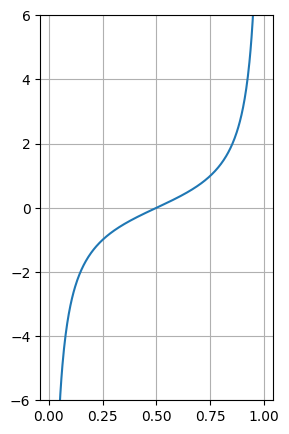

In [21]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0.01, 0.99, 400)
plt.figure(figsize=(3, 5))
plt.plot(x, np.tan(np.pi * x - np.pi / 2))
plt.ylim(-6, 6)
plt.grid()
plt.show()

Also ist auch $\mathbb{R}$ überabzählbar.

| Menge | Mächtigkeit |
|---|---|
| $\mathbb{N}$, $\mathbb{N}_0$, $\mathbb{Z}$, $\mathbb{Q}$ | abzählbar unendlich |
| $\mathbb{R}$, das Intervall $(0, 1)$, alle 0-1-Folgen, alle Teilmengen von $\mathbb{N}$ | überabzählbar |

### Wie viele Probleme sind algorithmisch nicht lösbar?

**Es gibt nur abzählbar viele Algorithmen.** Jedes Programm ist ein endlicher Text. Jedes Zeichen ist im Rechner
eine Folge von Bytes, alle Bytes zusammen ergeben eine (große) binäre Zahl. Verschiedene Programme ergeben
verschiedene Zahlen:

In [22]:
zahl = int.from_bytes(text.encode('utf-8'), 'big')
print(zahl)
print(zahl.to_bytes(len(text.encode('utf-8')), 'big').decode('utf-8'))

195036360130892016852252709078808112339893680133339353280920066949601281285880696305674
def verdoppeln(x):
    return 2 * x



Die Zahl ist lang, aber endlich, und aus ihr lässt sich das Programm `verdoppeln` wieder zurückgewinnen. Also gibt
es höchstens so viele Programme wie natürliche Zahlen.

**Es gibt überabzählbar viele Entscheidungsprobleme.** Schon wenn wir nur Fragen über natürliche Zahlen nehmen
(„Ist $n$ eine Primzahl?“, „Ist $n$ gerade?“, ...), ist jedes solche Problem eine 0-1-Folge: An der Stelle $n$ steht
1 für Ja und 0 für Nein. Es gibt also so viele Entscheidungsprobleme wie 0-1-Folgen, und die sind überabzählbar,
also so viele wie reelle Zahlen.

Jedes Programm entscheidet höchstens ein Problem. Den abzählbar vielen Programmen stehen überabzählbar viele Probleme
gegenüber. **Für fast alle Entscheidungsprobleme gibt es keinen Algorithmus.** „Fast alle“ heißt hier: alle bis auf
abzählbar viele.

#### Das Diagonalverfahren im Halteproblem

Der Beweis zum Halteproblem ist dasselbe Diagonalverfahren. Wir nummerieren alle Programme $p_1, p_2, p_3, \dots$
und schreiben in eine Tabelle, ob Programm $p_i$ angesetzt auf $p_j$ anhält (H) oder nicht (-):

|  | $p_1$ | $p_2$ | $p_3$ | $\dots$ |
|---|---|---|---|---|
| $p_1$ | **H** | - | H | |
| $p_2$ | - | **-** | H | |
| $p_3$ | H | H | **-** | |
| $\dots$ | | | | |

`quer` macht auf der Diagonalen genau das Gegenteil: `quer` angesetzt auf $p_i$ hält genau dann, wenn $p_i$
angesetzt auf $p_i$ nicht hält. Damit unterscheidet sich `quer` von jedem Programm der Tabelle, so wie die
Diagonalfolge von jeder Folge der Liste. Gäbe es `haltetest`, dann wäre `quer` aber ein Programm und müsste in der
Tabelle stehen. Das ist der Widerspruch.